# WheelNet: architecture and fitting strategy

What the wheel model looks like inside, what it is allowed to see, and how it is trained. Sections:

1. Architecture diagram and parameter budget
2. Tensor shapes through one forward pass
3. Attention masks: how "only what the drafter has seen" is enforced
4. Fitting strategy: chronological splits, loss, LR schedule, regularisation, experiment curves
5. Calibration and an example draft
6. Results across sets, and the weekly-retraining experiment (these fill in as runs finish)

Needs `data/features/MSH.PremierDraft/` and `results/MSH.PremierDraft/` (from `scripts/build_dataset.py`,
`scripts/train_nn.py`). Everything runs on CPU in about a minute.

In [1]:
import json
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Patch

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from openlane.data import N_PACKS, N_SEATS, load_tensors
from openlane.evaluate import metrics
from openlane.features import wheel_tensors
from openlane.nn import DraftDataset, WheelNet, collate, draft_context

SET, EVENT = "MSH", "PremierDraft"
OUT = ROOT / "results" / f"{SET}.{EVENT}"

# reference categorical palette, fixed order (same as results.ipynb)
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})

t = load_tensors(SET, EVENT)
passed, back = wheel_tensors(t)
meta = pickle.load(open(ROOT / "data" / "features" / f"{SET}.{EVENT}" / "meta.pkl", "rb"))
ckpt = torch.load(OUT / "models" / "wheelnet.pt", map_location="cpu", weights_only=False)
model = WheelNet(len(t.names), card_feats=ckpt["card_feats"], **ckpt["cfg"]).eval()
model.load_state_dict(ckpt["state"])
print(f"{SET}: {len(t.draft_id):,} drafts, {len(t.names)} cards, {t.n_picks}-card packs; "
      f"model config {ckpt['cfg'] or 'defaults'}")

MSH: 68,609 drafts, 339 cards, 14-card packs; model config defaults


## 1. Architecture

Two stacks share one card-embedding table.

* **History encoder** reads the draft so far as one token per pick (42 for 14-card packs). Each token sums
  the pack shown (count-weighted mean of card embeddings), the card taken, the cards the other seven
  drafters took from a pack that has come back (picks 9-14 only), and a learned position. Self-attention
  is causal, so token *t* sees picks up to *t*.
* **Pack decoder** scores the cards passed at each wheel-eligible pick (picks 1-6 of each pack). A card
  token is its embedding + copy count + which wheel pick this is + a projection of the history state at
  that pick. Each layer does self-attention among the cards in the same pack (they shield each other),
  then cross-attention to the history up to that pick, then a feed-forward block.
* **Card embedding** = a learned vector + a linear map of known attributes (colours, rarity, mana value,
  creature, bonus sheet), so colour information is there from the first step.

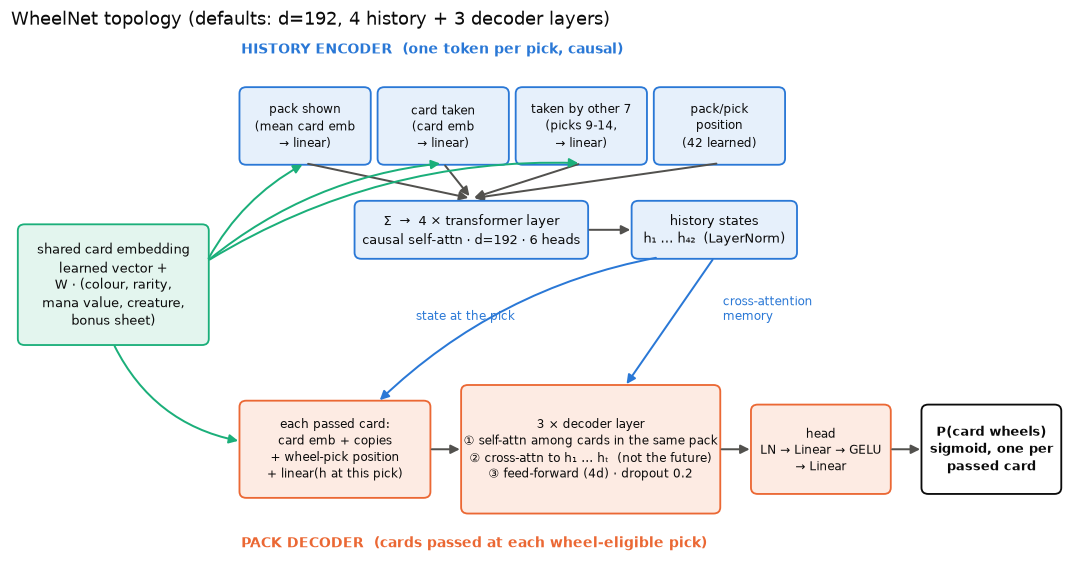

In [2]:
def box(ax, x, y, w, h, text, fc, ec, fs=9, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=INK,
            fontweight="bold" if bold else "normal", linespacing=1.35)

def arrow(ax, a, b, color=MUTED, rad=0.0, style="-|>"):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle=style, mutation_scale=12, color=color, lw=1.3,
                                 connectionstyle=f"arc3,rad={rad}", shrinkA=2, shrinkB=2))

HIST_FC, DEC_FC, EMB_FC = "#e6f0fb", "#fdebe3", "#e3f5ee"
fig, ax = plt.subplots(figsize=(12.5, 6.2))
ax.set_xlim(0, 12.5); ax.set_ylim(-0.3, 6.4); ax.axis("off"); ax.grid(False)

# shared card embedding
box(ax, 0.1, 2.45, 2.2, 1.5, "shared card embedding\nlearned vector +\nW · (colour, rarity,\nmana value, creature,\nbonus sheet)", EMB_FC, AQUA, fs=8.5)

# history lane
ax.text(2.7, 6.15, "HISTORY ENCODER  (one token per pick, causal)", color=BLUE, fontsize=9, fontweight="bold")
ins = ["pack shown\n(mean card emb\n→ linear)", "card taken\n(card emb\n→ linear)",
       "taken by other 7\n(picks 9-14,\n→ linear)", "pack/pick\nposition\n(42 learned)"]
for i, s in enumerate(ins):
    box(ax, 2.7 + i * 1.62, 4.75, 1.5, 0.95, s, HIST_FC, BLUE, fs=8)
    arrow(ax, (3.45 + i * 1.62, 4.75), (5.4, 4.3))
box(ax, 4.05, 3.55, 2.7, 0.7, "Σ  →  4 × transformer layer\ncausal self-attn · d=192 · 6 heads", HIST_FC, BLUE, fs=8.5)
box(ax, 7.3, 3.55, 1.9, 0.7, "history states\nh₁ … h₄₂  (LayerNorm)", HIST_FC, BLUE, fs=8.5)
arrow(ax, (6.75, 3.9), (7.3, 3.9))
for i in range(3):
    arrow(ax, (2.3, 3.5), (3.45 + i * 1.62, 4.75), color=AQUA, rad=-0.15)

# decoder lane
ax.text(2.7, -0.15, "PACK DECODER  (cards passed at each wheel-eligible pick)", color=ORANGE, fontsize=9, fontweight="bold")
box(ax, 2.7, 0.5, 2.2, 1.2, "each passed card:\ncard emb + copies\n+ wheel-pick position\n+ linear(h at this pick)", DEC_FC, ORANGE, fs=8)
box(ax, 5.3, 0.3, 3.0, 1.6, "3 × decoder layer\n① self-attn among cards in the same pack\n② cross-attn to h₁ … hₜ  (not the future)\n③ feed-forward (4d) · dropout 0.2", DEC_FC, ORANGE, fs=8)
box(ax, 8.7, 0.55, 1.6, 1.1, "head\nLN → Linear → GELU\n→ Linear", DEC_FC, ORANGE, fs=8)
box(ax, 10.7, 0.55, 1.6, 1.1, "P(card wheels)\nsigmoid, one per\npassed card", "#ffffff", INK, fs=8.5, bold=True)
arrow(ax, (4.9, 1.1), (5.3, 1.1)); arrow(ax, (8.3, 1.1), (8.7, 1.1)); arrow(ax, (10.3, 1.1), (10.7, 1.1))
arrow(ax, (1.2, 2.45), (2.7, 1.2), color=AQUA, rad=0.25)
arrow(ax, (8.25, 3.55), (7.2, 1.9), color=BLUE, rad=0.0)       # cross-attention memory
arrow(ax, (7.6, 3.55), (4.3, 1.7), color=BLUE, rad=0.15)       # ctx(state)
ax.text(8.35, 2.75, "cross-attention\nmemory", color=BLUE, fontsize=8)
ax.text(4.75, 2.75, "state at the pick", color=BLUE, fontsize=8)
ax.set_title("WheelNet topology (defaults: d=192, 4 history + 3 decoder layers)", loc="left", color=INK)
plt.show()

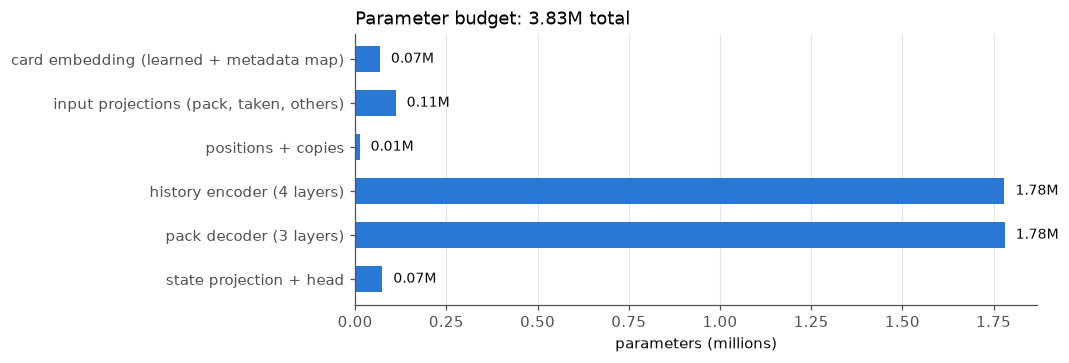

In [3]:
groups = {
    "card embedding (learned + metadata map)": ["card_", "feat_proj"],
    "input projections (pack, taken, others)": ["bag", "others", "taken"],
    "positions + copies": ["pos", "pick_pos", "copies"],
    "history encoder (4 layers)": ["hist", "hist_norm"],
    "pack decoder (3 layers)": ["packenc"],
    "state projection + head": ["ctx", "head"],
}
counts = {g: sum(p.numel() for n, p in model.named_parameters() if n.split(".")[0] in mods)
          for g, mods in groups.items()}
assert sum(counts.values()) == sum(p.numel() for p in model.parameters())
fig, ax = plt.subplots(figsize=(8, 3.2))
names, vals = list(counts)[::-1], [counts[g] / 1e6 for g in list(counts)[::-1]]
ax.barh(names, vals, color=BLUE, height=0.6)
for i, v in enumerate(vals):
    ax.text(v + 0.03, i, f"{v:.2f}M", va="center", color=INK, fontsize=9)
ax.set_xlabel("parameters (millions)"); ax.grid(axis="y", visible=False)
ax.set_title(f"Parameter budget: {sum(counts.values())/1e6:.2f}M total", loc="left")
plt.show()

## 2. Shapes through one forward pass

A batch of 4 real drafts, with hooks on each stage. `B` = drafts, 42 = picks, 18 = wheel-eligible picks
(3 packs × 6), 13 = the most distinct cards a passed pack can hold, 234 = 18 × 13 card slots per draft.
Packs are stored sparsely: each pick is a list of up to 14 distinct card ids with counts, not a 339-wide
vector.

In [4]:
test_idx = meta["splits"]["test"]
ds = DraftDataset(t, passed, back, test_idx[:64],
                 draft_context(t, **ckpt["inputs"]) if "inputs" in ckpt else None)
batch = collate([ds[i] for i in range(4)])
names_in = ["pack ids", "pack counts", "others ids", "others counts", "pick", "passed card ids",
            "copies", "label", "mask", "draft context"]
rows = [{"stage": f"input: {n}", "shape": str(tuple(x.shape)), "dtype": str(x.dtype).replace("torch.", "")}
        for n, x in zip(names_in, batch)]
seen = []
hooks = [getattr(model, m).register_forward_hook(
    lambda mod, i, o, m=m: seen.append({"stage": m, "shape": str(tuple(o.shape)), "dtype": str(o.dtype).replace("torch.", "")}))
    for m in ["hist", "packenc", "head"]]
*x, label, mask, ctx = batch
with torch.no_grad():
    out = model(*x, mask, ctx)
for h in hooks:
    h.remove()
labels = {"hist": "history encoder output", "packenc": "pack decoder output (18 packs × 13 slots, flattened)",
          "head": "head output"}
rows += [{**r, "stage": labels[r["stage"]]} for r in seen]
rows.append({"stage": "logits (per draft, pack, wheel pick, card slot)", "shape": str(tuple(out.shape)), "dtype": "float32"})
pl.Config.set_tbl_rows(20); pl.Config.set_fmt_str_lengths(60)
pl.DataFrame(rows)

stage,shape,dtype
str,str,str
"""input: pack ids""","""(4, 42, 14)""","""int16"""
"""input: pack counts""","""(4, 42, 14)""","""int8"""
"""input: others ids""","""(4, 42, 13)""","""int16"""
"""input: others counts""","""(4, 42, 13)""","""int8"""
"""input: pick""","""(4, 42)""","""int64"""
"""input: passed card ids""","""(4, 3, 6, 13)""","""int64"""
"""input: copies""","""(4, 3, 6, 13)""","""int64"""
"""input: label""","""(4, 3, 6, 13)""","""bool"""
"""input: mask""","""(4, 3, 6, 13)""","""bool"""


## 3. Attention masks: what the model may look at

Leakage is prevented structurally, by masks, not by feature engineering. Blue cells may attend; pale
cells are blocked.

* **History self-attention** is causal: pick *t* sees picks ≤ *t*.
* **Cross-attention** from the cards passed at a wheel pick sees history up to and including that pick
  (you know what you just took), never the returning pack.
* **Pack self-attention** is block-diagonal: the 18 packs of a draft share one sequence for speed, but
  cards only attend to cards in their own pack.

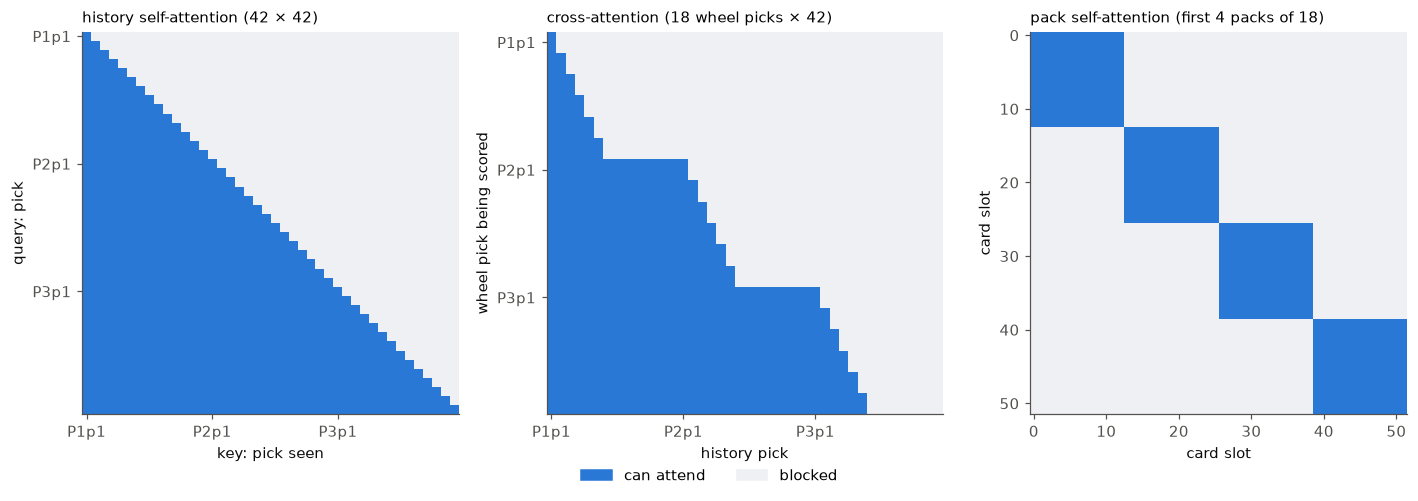

In [5]:
from matplotlib.colors import ListedColormap
cm = ListedColormap(["#eef0f3", BLUE])
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.05, 1]})
T = N_PACKS * t.n_picks
panels = [
    (~model.causal.numpy(), "history self-attention (42 × 42)", "key: pick seen", "query: pick"),
    (~model.future_tok.numpy()[::model.max_pass], "cross-attention (18 wheel picks × 42)", "history pick", "wheel pick being scored"),
    (~model.block.numpy()[:4 * model.max_pass, :4 * model.max_pass], "pack self-attention (first 4 packs of 18)", "card slot", "card slot"),
]
for ax, (m, title, xl, yl) in zip(axes, panels):
    ax.imshow(m, cmap=cm, interpolation="nearest", aspect="auto")
    ax.set_title(title, loc="left", fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.grid(False)
for ax in axes[:2]:
    ax.set_xticks([k * t.n_picks for k in range(3)], ["P1p1", "P2p1", "P3p1"])
axes[0].set_yticks([k * t.n_picks for k in range(3)], ["P1p1", "P2p1", "P3p1"])
axes[1].set_yticks([k * model.W for k in range(3)], ["P1p1", "P2p1", "P3p1"])
fig.legend(handles=[Patch(color=BLUE, label="can attend"), Patch(color="#eef0f3", label="blocked")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(); plt.show()

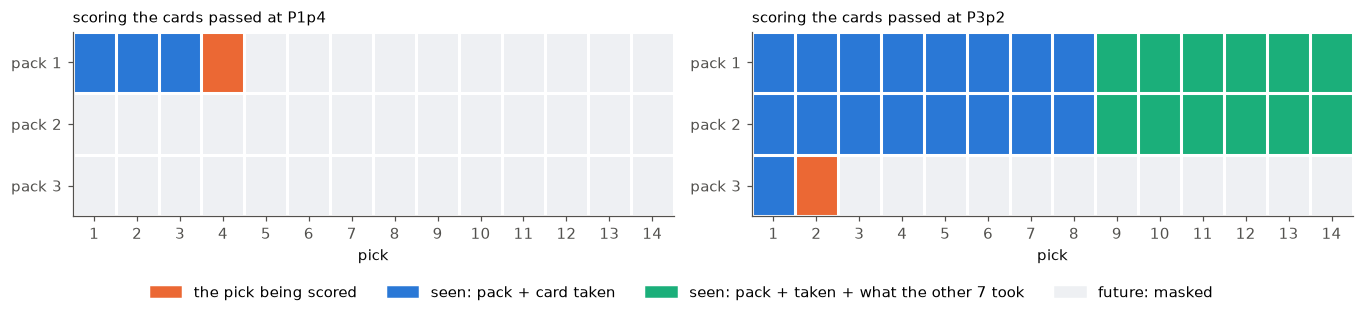

In [6]:
def visibility(k_scored, p_scored):
    """Category of every history token when scoring pack k_scored, pick p_scored."""
    g = np.zeros((N_PACKS, t.n_picks), int)            # 0 hidden (future)
    for k in range(N_PACKS):
        for p in range(t.n_picks):
            if (k, p) <= (k_scored, p_scored):
                g[k, p] = 2 if p >= N_SEATS else 1   # 2 = also carries "taken by other 7"
    g[k_scored, p_scored] = 3
    return g

cmap4 = ListedColormap(["#eef0f3", BLUE, AQUA, ORANGE])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 2.6))
for ax, (k, p) in zip(axes, [(0, 3), (2, 1)]):
    ax.imshow(visibility(k, p), cmap=cmap4, vmin=0, vmax=3, aspect="auto")
    ax.set_xticks(range(t.n_picks), [str(i + 1) for i in range(t.n_picks)])
    ax.set_yticks(range(3), ["pack 1", "pack 2", "pack 3"]); ax.set_xlabel("pick")
    ax.set_xticks(np.arange(-.5, t.n_picks), minor=True); ax.set_yticks(np.arange(-.5, 3), minor=True)
    ax.grid(which="minor", color="white", lw=2); ax.grid(which="major", visible=False)
    ax.tick_params(which="minor", length=0)
    ax.set_title(f"scoring the cards passed at P{k+1}p{p+1}", loc="left", fontsize=10)
fig.legend(handles=[Patch(color=ORANGE, label="the pick being scored"), Patch(color=BLUE, label="seen: pack + card taken"),
                    Patch(color=AQUA, label="seen: pack + taken + what the other 7 took"),
                    Patch(color="#eef0f3", label="future: masked")], loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

## 4. Fitting strategy

| | |
|---|---|
| **Split** | chronological: first 70% of drafts train, next 15% validation, last 15% test. No draft appears in two splits, and the test period is strictly later than training. |
| **Loss** | binary cross-entropy over every real (non-padding) passed card at every wheel-eligible pick |
| **Optimiser** | AdamW, weight decay 0.01, batch 128 drafts, gradient-norm clip 1.0 |
| **Schedule** | one-cycle: 5% linear warm-up to 1e-3, cosine decay to ~0 over 8 epochs |
| **Regularisation** | dropout 0.2 in every attention and feed-forward block |
| **Model selection** | keep the epoch with the best validation log loss; the test set is scored once at the end |
| **Architecture search** | done on validation only (`val_only=1`); see the curves below |

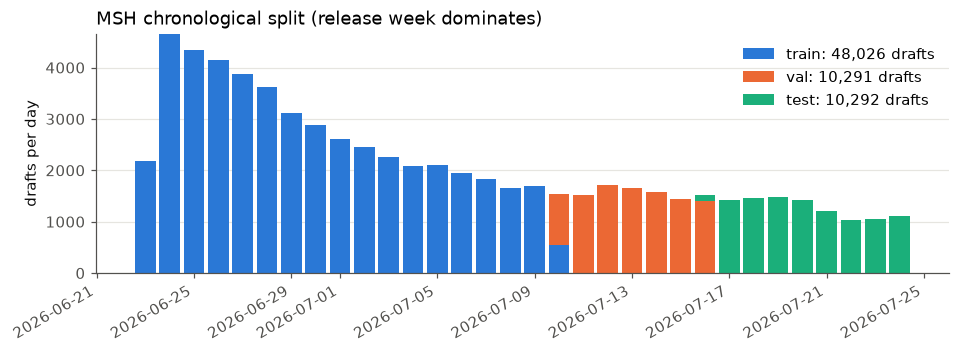

In [7]:
dt = np.array(meta["draft_time"], dtype="datetime64[D]")
days = np.arange(dt.min(), dt.max() + np.timedelta64(1, "D"))
fig, ax = plt.subplots(figsize=(10, 3.2))
bottom = np.zeros(len(days))
for (name, idx), color in zip(meta["splits"].items(), [BLUE, ORANGE, AQUA]):
    n = np.array([(dt[idx] == d).sum() for d in days])
    ax.bar(days, n, bottom=bottom, color=color, width=0.85, label=f"{name}: {len(idx):,} drafts")
    bottom += n
ax.set_ylabel("drafts per day"); ax.legend(loc="upper right"); ax.grid(axis="x", visible=False)
ax.set_title(f"{SET} chronological split (release week dominates)", loc="left")
fig.autofmt_xdate(); plt.show()

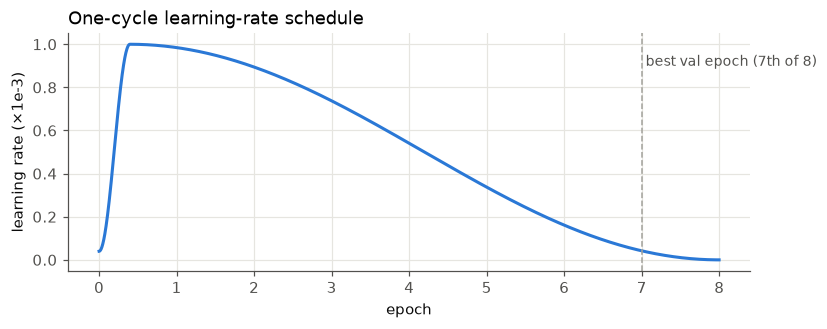

In [8]:
steps_per_epoch = int(np.ceil(len(meta["splits"]["train"]) / 128))
opt = torch.optim.AdamW([torch.nn.Parameter(torch.zeros(1))], lr=1e-3)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=8 * steps_per_epoch, pct_start=0.05)
lrs = []
for _ in range(8 * steps_per_epoch):
    lrs.append(sched.get_last_lr()[0]); opt.step(); sched.step()
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(np.arange(len(lrs)) / steps_per_epoch, np.array(lrs) * 1e3, color=BLUE)
ax.axvline(7, color=GRAY, ls="--", lw=1)
ax.text(7.05, 0.9, "best val epoch (7th of 8)", color=MUTED, fontsize=9)
ax.set_xlabel("epoch"); ax.set_ylabel("learning rate (×1e-3)")
ax.set_title("One-cycle learning-rate schedule", loc="left"); plt.show()

### Experiment curves (MSH validation set, this round of changes)

Each line is one training run, scored on the validation drafts after every epoch. The dashed line is
the previous WheelNet's best (0.4293). The first run (dropout 0.1, 12 epochs planned) was stopped once it
began to overfit.

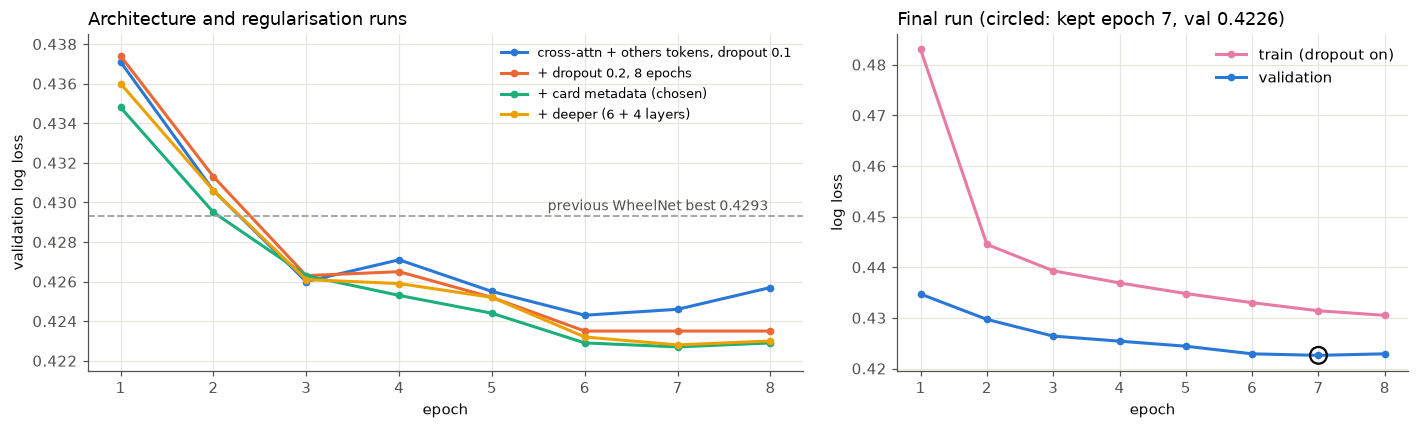

In [9]:
runs = {  # (train loss with dropout on, validation log loss) per epoch, from the training logs
    "cross-attn + others tokens, dropout 0.1": [(0.4869,0.4371),(0.4465,0.4306),(0.4400,0.4260),(0.4371,0.4271),(0.4351,0.4255),(0.4330,0.4243),(0.4308,0.4246),(0.4279,0.4257)],
    "+ dropout 0.2, 8 epochs": [(0.4837,0.4374),(0.4481,0.4313),(0.4415,0.4263),(0.4381,0.4265),(0.4360,0.4252),(0.4339,0.4235),(0.4323,0.4235),(0.4313,0.4235)],
    "+ card metadata (chosen)": [(0.4830,0.4348),(0.4445,0.4295),(0.4393,0.4263),(0.4369,0.4253),(0.4348,0.4244),(0.4330,0.4229),(0.4314,0.4227),(0.4305,0.4229)],
    "+ deeper (6 + 4 layers)": [(0.4834,0.4360),(0.4457,0.4306),(0.4397,0.4261),(0.4373,0.4259),(0.4353,0.4252),(0.4335,0.4232),(0.4320,0.4228),(0.4312,0.4230)],
}
final = [(0.4830,0.4347),(0.4445,0.4297),(0.4393,0.4264),(0.4369,0.4254),(0.4348,0.4244),(0.4330,0.4229),(0.4314,0.4226),(0.4305,0.4229)]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.4, 1]})
for (name, h), c in zip(runs.items(), [BLUE, ORANGE, AQUA, YELLOW]):
    v = [e[1] for e in h]
    a1.plot(range(1, len(v) + 1), v, color=c, marker="o", ms=4, label=name)
a1.axhline(0.4293, color=GRAY, ls="--", lw=1.2)
a1.text(5.6, 0.4296, "previous WheelNet best 0.4293", color=MUTED, fontsize=9)
a1.set_ylim(0.4215, 0.4385); a1.set_xlabel("epoch"); a1.set_ylabel("validation log loss")
a1.set_title("Architecture and regularisation runs", loc="left"); a1.legend(fontsize=8.5)
a2.plot(range(1, 9), [e[0] for e in final], color=MAGENTA, marker="o", ms=4, label="train (dropout on)")
a2.plot(range(1, 9), [e[1] for e in final], color=BLUE, marker="o", ms=4, label="validation")
best = int(np.argmin([e[1] for e in final]))
a2.scatter([best + 1], [final[best][1]], s=120, facecolor="none", edgecolor=INK, lw=1.5, zorder=5)
a2.set_xlabel("epoch"); a2.set_ylabel("log loss"); a2.legend()
a2.set_title(f"Final run (circled: kept epoch {best+1}, val {final[best][1]:.4f})", loc="left")
plt.tight_layout(); plt.show()

## 5. Calibration and an example draft

Calibration on the held-out test drafts: predictions are binned into 20 equal-count bins, and each dot
compares the mean predicted probability with the observed wheel rate. Points on the diagonal mean a
predicted 30% really wheels about 30% of the time.

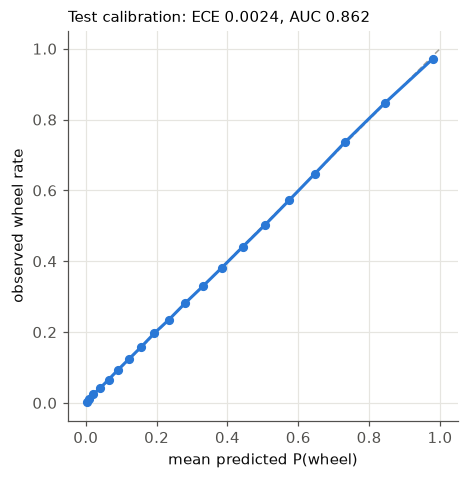

In [10]:
pred = pl.read_parquet(OUT / "test_predictions_wheelnet.parquet")
p, y = pred["wheelnet"].to_numpy(), pred["wheeled"].to_numpy()
q = np.quantile(p, np.linspace(0, 1, 21)); b = np.clip(np.searchsorted(q, p, side="right") - 1, 0, 19)
mp = np.bincount(b, p) / np.bincount(b); my = np.bincount(b, y) / np.bincount(b)
m = metrics(y, p)
fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.plot([0, 1], [0, 1], color=GRAY, lw=1, ls="--")
ax.plot(mp, my, color=BLUE, marker="o", ms=5)
ax.set_xlabel("mean predicted P(wheel)"); ax.set_ylabel("observed wheel rate")
ax.set_title(f"Test calibration: ECE {m['ece']:.4f}, AUC {m['auc']:.3f}", loc="left", fontsize=10)
ax.set_aspect("equal"); plt.show()

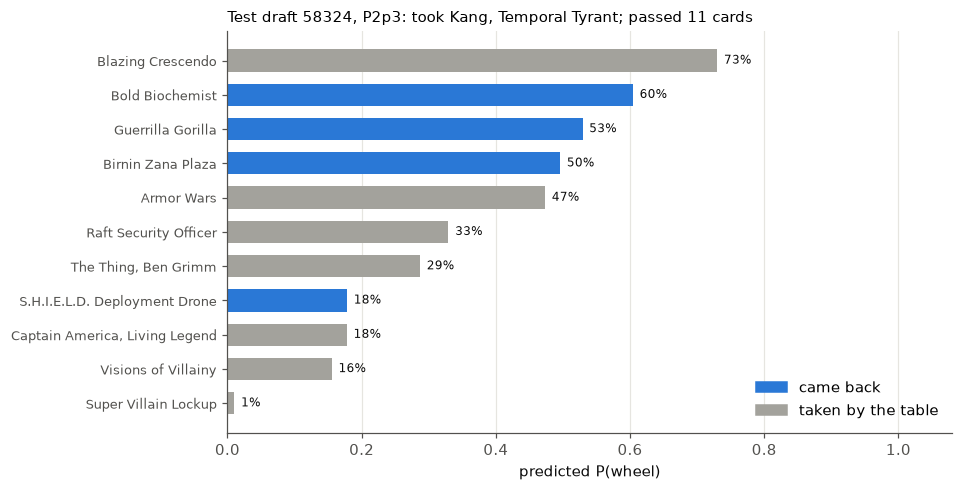

In [11]:
# one test draft, the cards passed at pack 2 pick 3
d, k, pk = 7, 1, 2
x = collate([ds[d]])
with torch.no_grad():
    prob = torch.sigmoid(model(*x[:7], x[8], x[9]))[0, k, pk].numpy()
msk, idx, lab = ds.mask[d, k, pk], ds.idx[d, k, pk], ds.label[d, k, pk]
order = np.argsort(prob[msk])
cards = [t.names[c] for c in idx[msk]]
fig, ax = plt.subplots(figsize=(8.5, 0.34 * msk.sum() + 1))
colors = [BLUE if w else GRAY for w in lab[msk][order]]
ax.barh(range(len(order)), prob[msk][order], color=colors, height=0.65)
ax.set_yticks(range(len(order)), [cards[i] for i in order], fontsize=8.5)
for i, v in enumerate(prob[msk][order]):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=8, color=INK)
ax.set_xlim(0, 1.08); ax.set_xlabel("predicted P(wheel)"); ax.grid(axis="y", visible=False)
taken = t.names[t.pick[test_idx[d], k, pk]]
ax.set_title(f"Test draft {test_idx[d]}, P{k+1}p{pk+1}: took {taken}; passed {msk.sum()} cards", loc="left", fontsize=10)
ax.legend(handles=[Patch(color=BLUE, label="came back"), Patch(color=GRAY, label="taken by the table")],
          loc="lower right")
plt.show()

## 6. Results across sets

Each set is trained and tested the same way as MSH (`scripts/run_all_sets.sh`). WheelNet gets fewer
epochs on bigger sets (`round(8 × 48k / training drafts)`, clamped to 3-8). The GBM and ALSA baseline are
fit on at most the 60k most recent training drafts to fit in 16GB. Bars show the relative log-loss
reduction against the ALSA/ATA baseline. Sets still running are skipped.

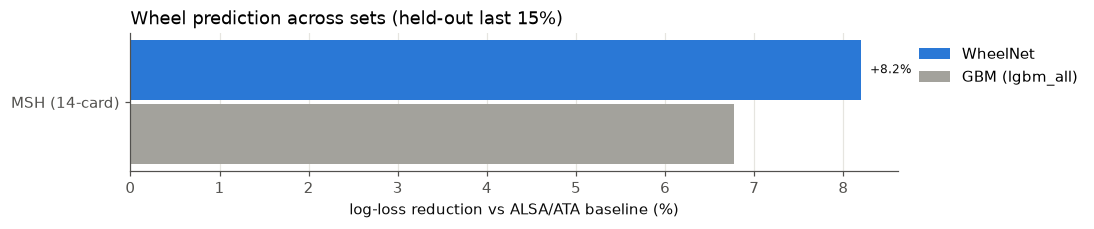

set,drafts,pack,alsa_logloss,lgbm_all,wheelnet,wheelnet_logloss,wheelnet_auc
str,i64,i64,f64,f64,f64,f64,f64
"""MSH""",68609,14,0.462869,0.067726,0.081992,0.424917,0.861826


In [12]:
rows = []
for f in sorted((ROOT / "results").glob("*.PremierDraft/summary.json")):
    s = {r["model"]: r for r in json.load(open(f))}
    if "wheelnet" not in s:
        continue
    fm = pickle.load(open(ROOT / "data" / "features" / f.parent.name / "meta.pkl", "rb"))
    rows.append({"set": f.parent.name.split(".")[0], "drafts": len(fm["draft_id"]),
                 "pack": fm.get("n_picks", 14), "alsa_logloss": s["alsa_ata_logreg"]["logloss"],
                 "lgbm_all": s["lgbm_all"]["vs_alsa"], "wheelnet": s["wheelnet"]["vs_alsa"],
                 "wheelnet_logloss": s["wheelnet"]["logloss"], "wheelnet_auc": s["wheelnet"]["auc"]})
sets = pl.DataFrame(rows).sort("wheelnet")
fig, ax = plt.subplots(figsize=(9, 0.42 * sets.height + 1.2))
yy = np.arange(sets.height)
ax.barh(yy + 0.2, sets["wheelnet"] * 100, height=0.38, color=BLUE, label="WheelNet")
ax.barh(yy - 0.2, sets["lgbm_all"] * 100, height=0.38, color=GRAY, label="GBM (lgbm_all)")
for i, v in enumerate(sets["wheelnet"]):
    ax.text(v * 100 + 0.1, i + 0.2, f"{v:+.1%}", va="center", fontsize=8, color=INK)
ax.set_yticks(yy, [f"{s} ({p}-card)" for s, p in zip(sets["set"], sets["pack"])])
ax.set_xlabel("log-loss reduction vs ALSA/ATA baseline (%)"); ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); ax.set_title("Wheel prediction across sets (held-out last 15%)", loc="left")
plt.show()
sets.sort("set")

### Weekly retraining (`scripts/temporal.py SET`)

Each line is scored on one week's drafts, using only earlier weeks for training. `frozen` never sees
anything after week 1; `retrain` starts over on everything so far; `finetune` / `replay` warm-start from
last week's model. The lookup arms show how much the raw card-level wheel rates drift.

In [13]:
files = sorted((ROOT / "results").glob("*.PremierDraft/temporal.json"))
if not files:
    print("no temporal.json yet: run  python scripts/temporal.py MSH")
for f in files:
    r = json.load(open(f))
    fig, ax = plt.subplots(figsize=(8, 3.4))
    arms = [("frozen", GRAY), ("retrain", BLUE), ("finetune", ORANGE), ("replay", AQUA)]
    for arm, c in arms:
        w = sorted(r["arms"][arm], key=int)
        ax.plot([int(i) + 1 for i in w], [r["arms"][arm][i]["logloss"] for i in w], color=c, marker="o", ms=5, label=arm)
    ax.set_xlabel("week scored"); ax.set_ylabel("WheelNet log loss")
    ax.set_title(f"{f.parent.name.split('.')[0]}: drafts per week {r['weeks']}", loc="left", fontsize=10)
    ax.legend(); plt.show()

no temporal.json yet: run  python scripts/temporal.py MSH
